# TRABAJO DE INVESTIGACIÓN DE OPERACIONES 1
## SIMULACIÓN DE EVENTOS DISCRETOS — DISTRIBUIDORA "DENLU"

**Objetivo:** validar con simulación el plan de personal obtenido por el modelo MILP (notebook `Denlu.ipynb`) y medir su robustez.

El modelo de colas $M/M/c$ analiza cada hora **por separado y en estado estable**. En la realidad la cola que se forma a las 9–10 h **se arrastra** a las horas siguientes, los almuerzos reducen la capacidad y la demanda varía día a día. La simulación de eventos discretos (SimPy) reproduce pedido por pedido una jornada completa (08:00–18:00) durante 299 días operativos para responder:

1. ¿El plan óptimo realmente elimina la pérdida de ruta? ¿Se cumple el 95 % de recuperación de ventas supuesto en el ROI?
2. ¿Hasta qué crecimiento de la demanda aguanta el plan?
3. ¿Qué pasa si falta personal (ausentismo)?
4. ¿Es $\rho = 0.85$ el mejor objetivo, considerando planilla + horas extra + ventas perdidas?
5. ¿Cambia la decisión si la venta perdida se valora a su margen bruto y no a precio de venta?

**Datos de entrada:** parámetros ya estimados en el diagnóstico (no requiere el CSV).

In [1]:
%pip install -q --disable-pip-version-check simpy ortools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import simpy
from ortools.linear_solver import pywraplp

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.edgecolor": "#52514e"})
COLOR = {"Actual": "#eb6834", "Óptimo": "#2a78d6", "Histórico": "#1baf7a"}

# --- Parámetros del diagnóstico (Denlu.ipynb) ---
MU_MIN = 44.5                  # tiempo medio de despacho (min/pedido), exponencial
MU_H = 60 / MU_MIN             # tasa de servicio individual (ped/h)
DIAS = 299                     # días operativos por año
HORAS = range(8, 18)
LAMBDA = {8: 1.599, 9: 6.742, 10: 6.268, 11: 3.064, 12: 1.324,
          13: 1.836, 14: 2.786, 15: 1.505, 16: 1.107, 17: 0.565}

# Resultados históricos 2025 con 3 despachadores (para calibrar y validar)
HIST_ESPERA = {8: 4.54, 9: 40.77, 10: 39.46, 11: 4.62, 12: 4.85, 13: 4.55, 14: 4.75, 15: 4.40, 16: 4.53, 17: 4.77}
HIST_PERDIDA = {8: 0, 9: 75.15, 10: 74.81, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0}
HIST_CANCEL = 10.0             # % de pedidos cancelados
HIST_VENTA_PERDIDA = 620_042.58
HIST_PEDIDOS = 8012
TICKET = HIST_VENTA_PERDIDA / round(HIST_PEDIDOS * HIST_CANCEL / 100)   # S/ por pedido cancelado

C_FT, C_PT = 1373.50, 686.76   # costo mensual por trabajador (S/)
CIERRE = 600                   # 18:00, en minutos desde las 08:00
COSTO_HORA_EXTRA = 1025 / 240 * 1.25   # hora simple del sueldo base + 25 % (D.S. 007-2002-TR)
MARGEN = 1.0                   # margen bruto de un pedido; 1.0 = venta perdida a precio de venta (como el notebook original)

HIST_PERDIDA_TOTAL = sum(HIST_PERDIDA[h] * LAMBDA[h] for h in HORAS) / sum(LAMBDA.values())
print(f"Pedidos/día esperados: {sum(LAMBDA.values()):.1f} | Ticket promedio de un pedido cancelado: S/ {TICKET:,.2f}")
print(f"Pérdida de ruta histórica sobre el total de pedidos: {HIST_PERDIDA_TOTAL:.1f} %")
print(f"Costo de una hora extra: S/ {COSTO_HORA_EXTRA:.2f}")

Note: you may need to restart the kernel to use updated packages.


Pedidos/día esperados: 26.8 | Ticket promedio de un pedido cancelado: S/ 774.09
Pérdida de ruta histórica sobre el total de pedidos: 36.4 %
Costo de una hora extra: S/ 5.34


## 1. Modelo de simulación

**Entidades:** pedidos. **Recursos:** despachadores. **Reloj:** minutos desde las 08:00.

| Elemento | Supuesto |
|---|---|
| Llegadas | Proceso de Poisson no homogéneo: tasa $\lambda_h$ constante dentro de cada hora |
| Servicio | Exponencial, media 44.5 min (consistente con el $M/M/c$ del diagnóstico) |
| Disciplina | FIFO, un solo almacén con $c_h$ despachadores activos |
| Turnos | Los del MILP, con almuerzo. Al salir (almuerzo o fin de turno) el despachador **termina el pedido en curso** |
| Situación actual | 3 despachadores de 08:00 a 18:00 sin descontar almuerzo (igual que el diagnóstico; escenario optimista) |
| Pérdida de ruta | Si un pedido espera más de **T** min, su camión sale sin él |
| Cancelación | Tras perder la ruta, el cliente cancela con probabilidad **p**; si no, sigue esperando y se despacha para otra ruta |
| Cierre | Lo pendiente a las 18:00 se despacha con horas extra (personal de las 17 h, mínimo 1) |
| Horas extra | Cada minuto trabajado después de las 18:00 se paga como hora extra: S/ 5.34/h (sueldo base / 240 h + 25 %) |
| Venta perdida | Cada cancelación pierde el ticket promedio histórico, valorado al margen bruto (`MARGEN`; 100 % = precio de venta) |

**T** y **p** no se conocen: se **calibran** para que la situación actual simulada reproduzca los indicadores de 2025.

Para modelar la capacidad variable se usa un `PriorityResource`: cuando un despachador sale de turno, un "bloqueo" de prioridad alta ocupa su puesto apenas termina su pedido actual.

In [2]:
TURNOS = {                      # horas (inicio de cada intervalo) en que trabaja cada turno
    "FT-1": [8, 9, 10, 11, 13, 14, 15, 16],    # 08-17, almuerzo 12-13
    "FT-2": [8, 9, 10, 11, 12, 14, 15, 16],    # 08-17, almuerzo 13-14
    "FT-3": [9, 10, 11, 12, 13, 15, 16, 17],   # 09-18, almuerzo 14-15
    "PT-1": [9, 10, 11, 12],                   # 09-13
    "PT-2": [10, 11, 12, 13],                  # 10-14
    "PT-3": [14, 15, 16, 17],                  # 14-18
    "ACTUAL": list(HORAS),                     # situación actual (supuesto del diagnóstico)
}
PLAN_ACTUAL = {"ACTUAL": 3}
PLAN_OPTIMO = {"FT-1": 3, "FT-3": 1, "PT-1": 2}   # solución MILP con rho = 0.85


def costo_mensual(plan):
    return sum(n * (C_PT if t.startswith("PT") else C_FT) for t, n in plan.items())


def personal_por_hora(plan):
    return {h: sum(n for t, n in plan.items() if h in TURNOS[t]) for h in HORAS}


def simular_dia(personal_h, lam, T, p_cancel, rng):
    # Devuelve una fila por pedido: (hora de llegada, espera en min, perdió ruta, cancelado)
    # y los minutos-persona trabajados después del cierre de las 18:00 (horas extra).
    env = simpy.Environment()
    cap = max(1, max(personal_h.values()))
    almacen = simpy.PriorityResource(env, capacity=cap)
    registros = []
    extra_min = 0.0

    def control_turnos():
        bloqueos = []
        for n in [personal_h[h] for h in HORAS] + [max(1, personal_h[17])]:   # último = horas extra
            while len(bloqueos) < cap - n:
                bloqueos.append(almacen.request(priority=-1))
            while len(bloqueos) > cap - n:
                b = bloqueos.pop()
                almacen.release(b) if b.triggered else b.cancel()
            yield env.timeout(60)

    def pedido(h):
        nonlocal extra_min
        llegada = env.now
        req = almacen.request(priority=0)
        yield req | env.timeout(T)
        perdio_ruta = not req.triggered
        if perdio_ruta and rng.random() < p_cancel:
            req.cancel()
            registros.append((h, T, True, True))
            return
        yield req
        registros.append((h, env.now - llegada, perdio_ruta, False))
        duracion = rng.exponential(MU_MIN)
        extra_min += max(0.0, env.now + duracion - max(env.now, CIERRE))
        yield env.timeout(duracion)
        almacen.release(req)

    llegadas = sorted((60 * (h - 8) + u, h) for h in HORAS for u in rng.uniform(0, 60, rng.poisson(lam[h])))

    def generador():
        for t, h in llegadas:
            yield env.timeout(t - env.now)
            env.process(pedido(h))

    env.process(control_turnos())
    env.process(generador())
    env.run()
    return registros, extra_min


def simular_anio(plan, T, p_cancel, seed, crecimiento=0.0, ausentismo=0.0):
    # Un año = 299 jornadas independientes. Ausentismo: cada trabajador falta con esa probabilidad diaria.
    rng = np.random.default_rng(seed)
    lam = {h: LAMBDA[h] * (1 + crecimiento) for h in HORAS}
    filas, extra_min = [], 0.0
    for _ in range(DIAS):
        presentes = {t: rng.binomial(n, 1 - ausentismo) for t, n in plan.items()}
        registros, extra = simular_dia(personal_por_hora(presentes), lam, T, p_cancel, rng)
        filas += registros
        extra_min += extra
    df = pd.DataFrame(filas, columns=["hora", "espera", "perdio_ruta", "cancelado"])
    df.attrs["horas_extra"] = extra_min / 60
    return df


def indicadores(df, plan):
    venta_perdida = df["cancelado"].sum() * TICKET
    planilla = 12 * costo_mensual(plan)
    horas_extra = df.attrs["horas_extra"]
    return {"Pedidos": len(df),
            "Espera media (min)": df["espera"].mean(),
            "Espera 9-11h (min)": df.loc[df["hora"].isin([9, 10]), "espera"].mean(),
            "Pérdida ruta (%)": 100 * df["perdio_ruta"].mean(),
            "Cancelados (%)": 100 * df["cancelado"].mean(),
            "Venta perdida (S/)": venta_perdida,
            "Margen perdido (S/)": venta_perdida * MARGEN,
            "Horas extra (h/año)": horas_extra,
            "Costo horas extra (S/)": horas_extra * COSTO_HORA_EXTRA,
            "Planilla anual (S/)": planilla,
            "Costo total (S/)": planilla + horas_extra * COSTO_HORA_EXTRA + venta_perdida * MARGEN}


R = 10                 # réplicas (años simulados) por escenario
T_STUDENT = 2.262      # t(0.975, R-1 = 9) para intervalos de confianza al 95 %


def replicar(plan, T, p, **kw):
    # Mismas semillas en todos los escenarios = números aleatorios comunes (reduce varianza al comparar)
    return pd.DataFrame([indicadores(simular_anio(plan, T, p, seed=s, **kw), plan) for s in range(R)])


def media_ic(reps):
    return pd.DataFrame({"Media": reps.mean(), "± IC 95%": T_STUDENT * reps.std() / np.sqrt(R)})

## 2. Calibración y validación del modelo

Se buscan **T** (umbral de espera para perder la ruta) y **p** (probabilidad de cancelar tras perderla) que hagan que la operación actual simulada reproduzca los dos indicadores globales de 2025:

* Pérdida de ruta sobre el total de pedidos ≈ 36.4 %
* Pedidos cancelados ≈ 10 %

Se minimiza el error cuadrático sobre una grilla, promediando 4 años simulados por punto.

In [3]:
grilla = []
for T in [15, 20, 25]:
    for p in [0.24, 0.26, 0.28, 0.30, 0.32]:
        sims = pd.concat([simular_anio(PLAN_ACTUAL, T, p, seed=1000 + s) for s in range(4)])
        perdida, cancel = 100 * sims["perdio_ruta"].mean(), 100 * sims["cancelado"].mean()
        grilla.append({"T": T, "p": p, "Pérdida (%)": perdida, "Cancel (%)": cancel,
                       "Error": (perdida - HIST_PERDIDA_TOTAL) ** 2 + (cancel - HIST_CANCEL) ** 2})
grilla = pd.DataFrame(grilla)
mejor = grilla.loc[grilla["Error"].idxmin()]
T_CAL, P_CAL = float(mejor["T"]), float(mejor["p"])

display(grilla.pivot(index="T", columns="p", values="Error").round(1)
        .style.background_gradient(cmap="Blues_r").set_caption("Error de calibración (menor = mejor)"))
print(f"Calibrado: T = {T_CAL:.0f} min, p = {P_CAL:.2f} -> pérdida {mejor['Pérdida (%)']:.1f} %, cancelados {mejor['Cancel (%)']:.1f} %")

p,0.240000,0.260000,0.280000,0.300000,0.320000
T,,,,,
15,18.900000,14.900000,11.100000,8.800000,9.100000
20,1.600000,0.300000,0.300000,2.600000,2.900000
25,4.800000,2.700000,3.900000,14.800000,6.000000


Calibrado: T = 20 min, p = 0.28 -> pérdida 36.8 %, cancelados 10.3 %


,8,9,10,11,12,13,14,15,16,17
Espera hist. (min),4.5,40.8,39.5,4.6,4.8,4.6,4.8,4.4,4.5,4.8
Espera sim. (min),0.5,15.3,36.4,37.4,23.0,12.1,10.0,7.6,3.9,0.9
Pérdida hist. (%),0.0,75.2,74.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Pérdida sim. (%),1.1,31.2,65.0,60.4,39.2,21.7,18.7,14.4,7.7,2.1


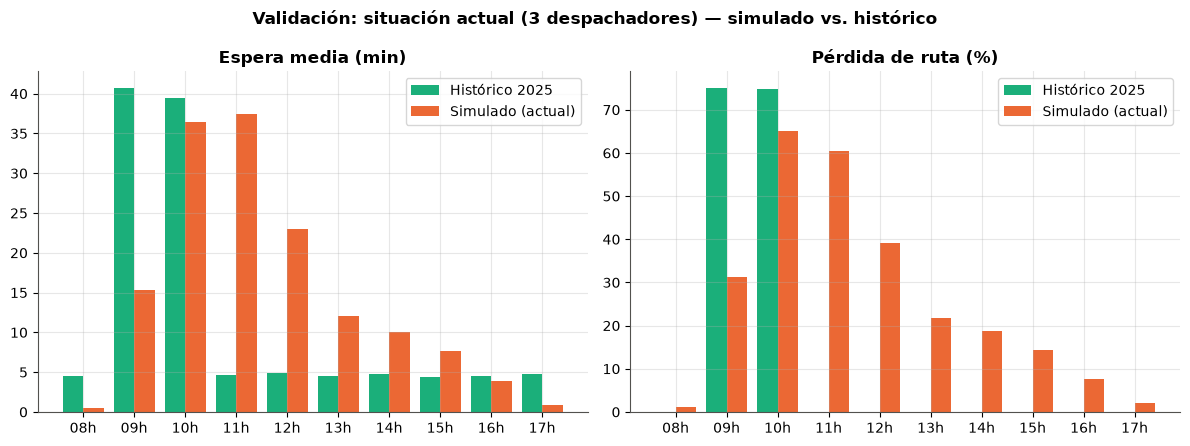

In [4]:
# Validación hora por hora: situación actual simulada vs. histórico 2025
sim_actual = pd.concat([simular_anio(PLAN_ACTUAL, T_CAL, P_CAL, seed=s) for s in range(R)])
por_hora = sim_actual.groupby("hora").agg(espera=("espera", "mean"), perdida=("perdio_ruta", "mean"))
display(pd.DataFrame({"Espera hist. (min)": HIST_ESPERA, "Espera sim. (min)": por_hora["espera"],
                      "Pérdida hist. (%)": HIST_PERDIDA, "Pérdida sim. (%)": 100 * por_hora["perdida"]}).round(1).T)

fig, ax = plt.subplots(1, 2)
x = np.arange(len(HORAS)); etiquetas = [f"{h:02d}h" for h in HORAS]
for a, col, hist, titulo in [(ax[0], "espera", HIST_ESPERA, "Espera media (min)"),
                             (ax[1], "perdida", HIST_PERDIDA, "Pérdida de ruta (%)")]:
    valores = por_hora[col] * (100 if col == "perdida" else 1)
    a.bar(x - 0.2, [hist[h] for h in HORAS], 0.4, label="Histórico 2025", color=COLOR["Histórico"])
    a.bar(x + 0.2, valores, 0.4, label="Simulado (actual)", color=COLOR["Actual"])
    a.set_xticks(x, etiquetas); a.set_title(titulo, fontweight="bold"); a.legend()
plt.suptitle("Validación: situación actual (3 despachadores) — simulado vs. histórico", fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura:** la simulación reproduce los totales anuales (pérdida y cancelación), pero distribuye la congestión de otra manera: en el histórico la pérdida aparece solo a las 9–10 h y desaparece de golpe a las 11 h; en la simulación la cola formada en el pico **se arrastra hasta el mediodía**. Esto es lo que hace una cola real cuando $\rho > 1$ durante dos horas seguidas, y es precisamente el efecto que el análisis $M/M/c$ hora por hora no puede ver.

## 3. Escenario 1 — Situación actual vs. plan óptimo (MILP, $\rho = 0.85$)

In [5]:
reps = {"Actual": replicar(PLAN_ACTUAL, T_CAL, P_CAL), "Óptimo": replicar(PLAN_OPTIMO, T_CAL, P_CAL)}
tabla = pd.concat({k: media_ic(v) for k, v in reps.items()}, axis=1)
display(tabla.style.format("{:,.2f}"))

print("Despachadores por hora (plan óptimo):", personal_por_hora(PLAN_OPTIMO))

Despachadores por hora (plan óptimo): {8: 3, 9: 6, 10: 6, 11: 6, 12: 3, 13: 4, 14: 3, 15: 4, 16: 4, 17: 1}


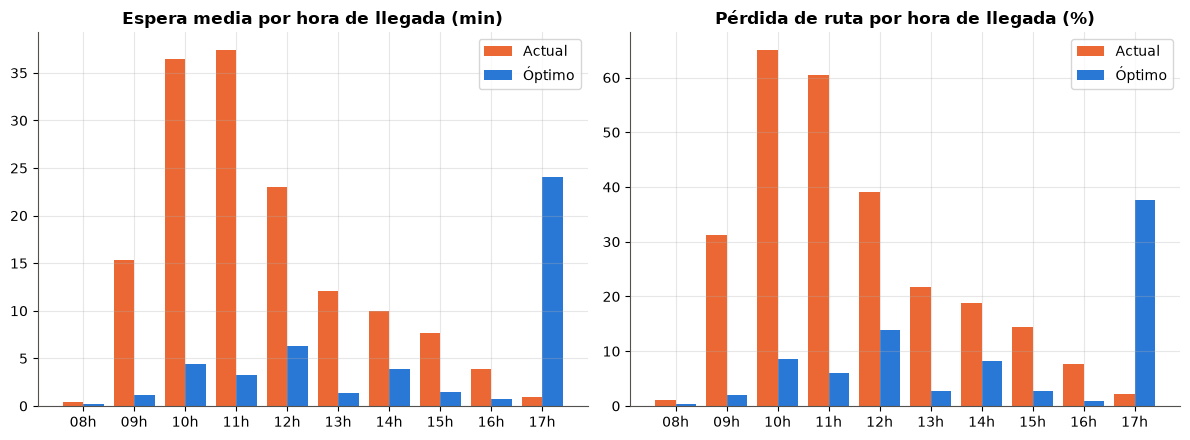

In [6]:
sim_opt = pd.concat([simular_anio(PLAN_OPTIMO, T_CAL, P_CAL, seed=s) for s in range(R)])
perfiles = {"Actual": sim_actual, "Óptimo": sim_opt}

fig, ax = plt.subplots(1, 2)
for i, (nombre, sim) in enumerate(perfiles.items()):
    g = sim.groupby("hora")
    ax[0].bar(x + (i - 0.5) * 0.4, g["espera"].mean(), 0.4, label=nombre, color=COLOR[nombre])
    ax[1].bar(x + (i - 0.5) * 0.4, 100 * g["perdio_ruta"].mean(), 0.4, label=nombre, color=COLOR[nombre])
ax[0].set_title("Espera media por hora de llegada (min)", fontweight="bold")
ax[1].set_title("Pérdida de ruta por hora de llegada (%)", fontweight="bold")
for a in ax: a.set_xticks(x, etiquetas); a.legend()
plt.tight_layout(); plt.show()

In [7]:
# ROI recalculado con la simulación (el notebook original supone 95 % de recuperación)
act, opt = reps["Actual"].mean(), reps["Óptimo"].mean()
costo_personal = lambda r: r["Planilla anual (S/)"] + r["Costo horas extra (S/)"]
inversion = costo_personal(opt) - costo_personal(act)
recuperado = act["Margen perdido (S/)"] - opt["Margen perdido (S/)"]
beneficio = recuperado - inversion

print("=== ROI SEGÚN SIMULACIÓN ===")
print(f"Venta perdida actual (simulada):   S/ {act['Venta perdida (S/)']:>12,.2f}  (histórico S/ {HIST_VENTA_PERDIDA:,.2f})")
print(f"Venta perdida con plan óptimo:     S/ {opt['Venta perdida (S/)']:>12,.2f}")
print(f"Recuperación de ventas:            {100 * recuperado / act['Venta perdida (S/)']:.1f} %  (supuesto original: 95 %)")
print(f"Horas extra al año:                {act['Horas extra (h/año)']:.0f} h actual (S/ {act['Costo horas extra (S/)']:,.0f}) | "
      f"{opt['Horas extra (h/año)']:.0f} h óptimo (S/ {opt['Costo horas extra (S/)']:,.0f})")
print(f"Inversión adicional (planilla + horas extra): S/ {inversion:,.2f}")
print(f"Beneficio neto anual (margen {100 * MARGEN:.0f} %): S/ {beneficio:,.2f}")
print(f"ROI:                               {100 * beneficio / inversion:,.0f} %")

=== ROI SEGÚN SIMULACIÓN ===
Venta perdida actual (simulada):   S/   634,595.39  (histórico S/ 620,042.58)
Venta perdida con plan óptimo:     S/    99,934.45
Recuperación de ventas:            84.3 %  (supuesto original: 95 %)
Horas extra al año:                134 h actual (S/ 716) | 138 h óptimo (S/ 737)
Inversión adicional (planilla + horas extra): S/ 32,985.66
Beneficio neto anual (margen 100 %): S/ 501,675.28
ROI:                               1,521 %


## 4. Escenario 2 — Crecimiento de la demanda

Se mantiene fijo el plan óptimo y se incrementan todas las tasas $\lambda_h$ en el mismo porcentaje.

,rho pico (9h),Espera 9-11h (min),Pérdida ruta (%),Cancelados (%),Horas extra (h/año),Venta perdida (S/)
Crecimiento,,,,,,
+0 %,0.83,2.68,5.90,1.61,138.12,"99,934.45"
+10 %,0.92,3.84,8.39,2.42,146.73,"165,112.46"
+20 %,1.00,5.00,10.92,3.05,172.98,"226,807.09"
+30 %,1.08,6.17,13.79,3.90,191.06,"314,123.94"
+40 %,1.17,8.06,17.54,4.99,200.61,"433,720.17"
+50 %,1.25,9.88,21.55,6.06,212.13,"564,618.05"


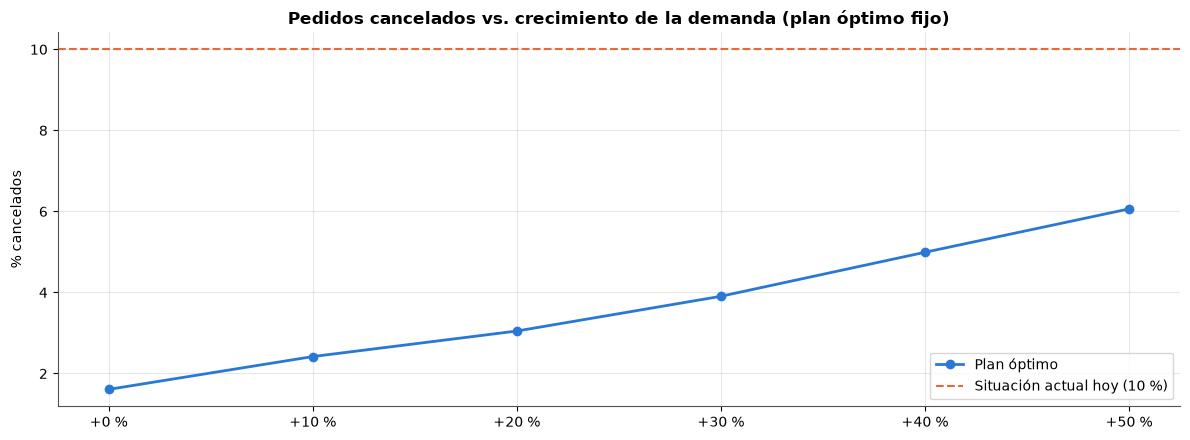

In [8]:
crec = []
for g in [0, 0.10, 0.20, 0.30, 0.40, 0.50]:
    r = replicar(PLAN_OPTIMO, T_CAL, P_CAL, crecimiento=g).mean()
    crec.append({"Crecimiento": f"+{100 * g:.0f} %", "rho pico (9h)": LAMBDA[9] * (1 + g) / (6 * MU_H), **r})
crec = pd.DataFrame(crec).set_index("Crecimiento")
display(crec[["rho pico (9h)", "Espera 9-11h (min)", "Pérdida ruta (%)", "Cancelados (%)", "Horas extra (h/año)", "Venta perdida (S/)"]]
        .style.format("{:,.2f}"))

fig, ax = plt.subplots()
ax.plot(crec.index, crec["Cancelados (%)"], marker="o", lw=2, color=COLOR["Óptimo"], label="Plan óptimo")
ax.axhline(HIST_CANCEL, ls="--", color=COLOR["Actual"], lw=1.5, label="Situación actual hoy (10 %)")
ax.set_title("Pedidos cancelados vs. crecimiento de la demanda (plan óptimo fijo)", fontweight="bold")
ax.set_ylabel("% cancelados"); ax.legend(); plt.tight_layout(); plt.show()

## 5. Escenario 3 — Ausentismo

Cada trabajador falta un día con probabilidad dada (independiente). No se reemplaza al ausente.

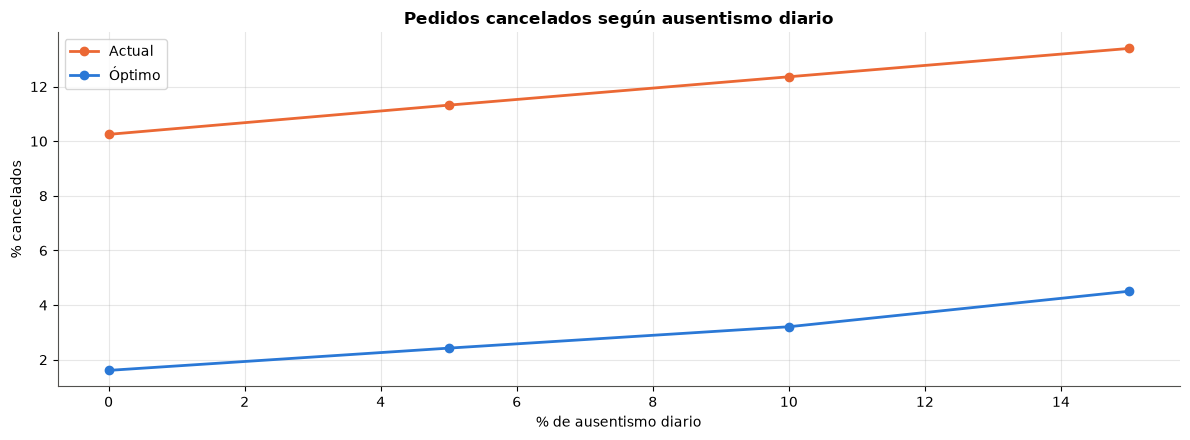

In [9]:
aus = []
for a in [0, 0.05, 0.10, 0.15]:
    for nombre, plan in [("Actual", PLAN_ACTUAL), ("Óptimo", PLAN_OPTIMO)]:
        r = replicar(plan, T_CAL, P_CAL, ausentismo=a).mean()
        aus.append({"Ausentismo (%)": round(100 * a), "Plan": nombre, **r})
aus = pd.DataFrame(aus)
display(aus.pivot(index="Ausentismo (%)", columns="Plan", values=["Cancelados (%)", "Horas extra (h/año)", "Venta perdida (S/)", "Costo total (S/)"])
        .style.format("{:,.2f}"))

fig, ax = plt.subplots()
for nombre in ["Actual", "Óptimo"]:
    d = aus[aus["Plan"] == nombre]
    ax.plot(d["Ausentismo (%)"], d["Cancelados (%)"], marker="o", lw=2, color=COLOR[nombre], label=nombre)
ax.set_title("Pedidos cancelados según ausentismo diario", fontweight="bold")
ax.set_xlabel("% de ausentismo diario"); ax.set_ylabel("% cancelados"); ax.legend(); plt.tight_layout(); plt.show()

## 6. Escenario 4 — Sensibilidad del $\rho$ objetivo

Para cada $\rho$ objetivo se recalcula $D_h$, se **re-optimiza el MILP** (mismo modelo del notebook original) y se simula el plan resultante. El mejor $\rho$ es el que minimiza **planilla + horas extra + ventas perdidas**.

,Plan,Personas,Cancelados (%),Horas extra (h/año),Planilla anual (S/),Costo horas extra (S/),Margen perdido (S/),Costo total (S/)
rho,,,,,,,,
0.500000,"FT-1:2, FT-2:4, FT-3:1, PT-1:4",11,0.33,132.79,"148,338.48",708.91,"20,203.63","169,251.02"
0.550000,"FT-1:5, FT-3:1, PT-1:4",10,0.23,126.83,"131,856.48",677.08,"13,933.54","146,467.10"
0.600000,"FT-1:5, FT-3:1, PT-1:3",9,0.32,117.26,"123,615.36",626.01,"19,584.37","143,825.74"
0.650000,"FT-1:4, FT-3:1, PT-1:3",8,0.42,127.93,"107,133.36",682.96,"25,777.05","133,593.37"
0.700000,"FT-1:4, FT-3:1, PT-1:3",8,0.42,127.93,"107,133.36",682.96,"25,777.05","133,593.37"
0.750000,"FT-1:4, FT-3:1, PT-1:2",7,0.82,138.89,"98,892.24",741.48,"51,167.06","150,800.78"
0.800000,"FT-1:4, FT-3:1, PT-1:2",7,0.82,138.89,"98,892.24",741.48,"51,167.06","150,800.78"
0.850000,"FT-1:3, FT-3:1, PT-1:2",6,1.61,138.12,"82,410.24",737.37,"99,934.45","183,082.06"
0.900000,"FT-1:3, FT-3:1, PT-1:2",6,1.61,138.12,"82,410.24",737.37,"99,934.45","183,082.06"


rho con menor costo total (margen 100 %): 0.65


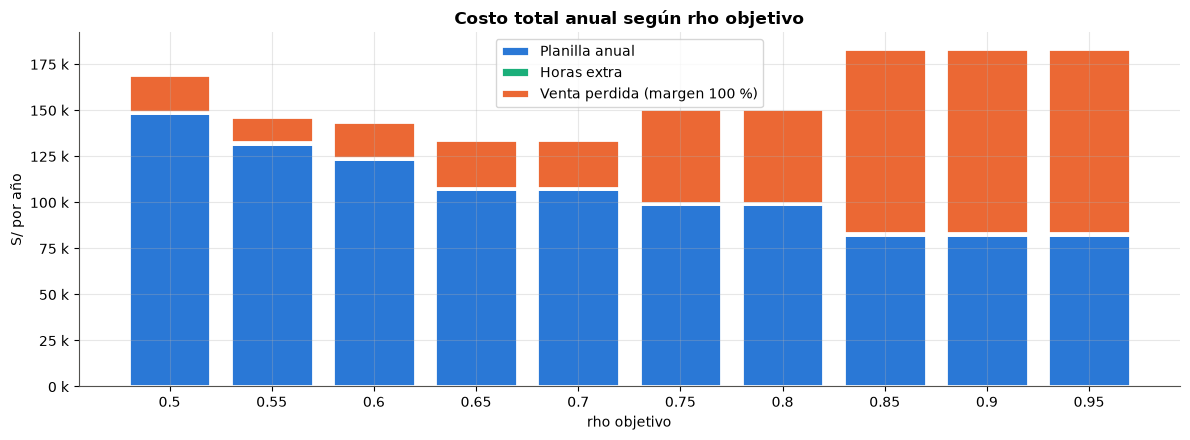

In [10]:
def optimizar(rho):
    req = {h: max(1, int(np.ceil(LAMBDA[h] / (rho * MU_H)))) for h in HORAS}
    s = pywraplp.Solver.CreateSolver("SCIP")
    x = {t: s.IntVar(0, 10, t) for t in TURNOS if t != "ACTUAL"}
    for h in HORAS:
        s.Add(sum(x[t] for t in x if h in TURNOS[t]) >= req[h])
    ft = sum(v for t, v in x.items() if t.startswith("FT"))
    pt = sum(v for t, v in x.items() if t.startswith("PT"))
    s.Add(-0.40 * ft + 0.60 * pt <= 0)                 # D.S. 003-97-TR: part-time <= 40 %
    s.Minimize(C_FT * ft + C_PT * pt)
    assert s.Solve() == pywraplp.Solver.OPTIMAL
    return {t: round(v.solution_value()) for t, v in x.items() if v.solution_value() > 0.5}

# Verificación: con rho = 0.85 se obtiene el mismo costo que en el notebook original
assert abs(costo_mensual(optimizar(0.85)) - 6867.52) < 0.01

sens = []
for rho in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]:
    plan = optimizar(rho)
    r = replicar(plan, T_CAL, P_CAL).mean()
    sens.append({"rho": rho, "Plan": ", ".join(f"{t}:{n}" for t, n in plan.items()),
                 "Personas": sum(plan.values()), **r})
sens = pd.DataFrame(sens).set_index("rho")
columnas = ["Cancelados (%)", "Horas extra (h/año)", "Planilla anual (S/)", "Costo horas extra (S/)", "Margen perdido (S/)", "Costo total (S/)"]
display(sens[["Plan", "Personas", *columnas]].style.format({c: "{:,.2f}" for c in columnas}))
rho_best = sens["Costo total (S/)"].idxmin()
print(f"rho con menor costo total (margen {100 * MARGEN:.0f} %): {rho_best:.2f}")

fig, ax = plt.subplots()
x_rho = sens.index.astype(str)
ax.bar(x_rho, sens["Planilla anual (S/)"], color=COLOR["Óptimo"], label="Planilla anual", edgecolor="white", lw=2)
ax.bar(x_rho, sens["Costo horas extra (S/)"], bottom=sens["Planilla anual (S/)"],
       color=COLOR["Histórico"], label="Horas extra", edgecolor="white", lw=2)
ax.bar(x_rho, sens["Margen perdido (S/)"], bottom=sens["Planilla anual (S/)"] + sens["Costo horas extra (S/)"],
       color=COLOR["Actual"], label=f"Venta perdida (margen {100 * MARGEN:.0f} %)", edgecolor="white", lw=2)
ax.set_title("Costo total anual según rho objetivo", fontweight="bold")
ax.set_xlabel("rho objetivo"); ax.set_ylabel("S/ por año"); ax.legend()
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f} k")
plt.tight_layout(); plt.show()

## 7. ¿Qué $\rho$ conviene según el margen bruto?

Cuando se cancela un pedido, DENLU no pierde toda la venta: pierde el **margen bruto** de ese pedido, porque tampoco gasta en la mercadería que no vendió. El margen no cambia la operación simulada, así que basta con revalorar los resultados del escenario 4:

$$\text{Costo total} = \text{Planilla} + \text{Horas extra} + \text{margen} \times \text{Venta perdida}$$

Margen bruto,rho que minimiza el costo,Plan,Costo total (S/),Ahorro vs rho 0.85 (S/)
10 %,0.85,"FT-1:3, FT-3:1, PT-1:2","93,141",0
20 %,0.85,"FT-1:3, FT-3:1, PT-1:2","103,135",0
30 %,0.85,"FT-1:3, FT-3:1, PT-1:2","113,128",0
40 %,0.65,"FT-1:4, FT-3:1, PT-1:3","118,127","4,994"
50 %,0.65,"FT-1:4, FT-3:1, PT-1:3","120,705","12,410"
75 %,0.65,"FT-1:4, FT-3:1, PT-1:3","127,149","30,949"
100 %,0.65,"FT-1:4, FT-3:1, PT-1:3","133,593","49,489"


El plan de rho 0.65 conviene sobre el de rho 0.85 cuando el margen bruto supera 33 %


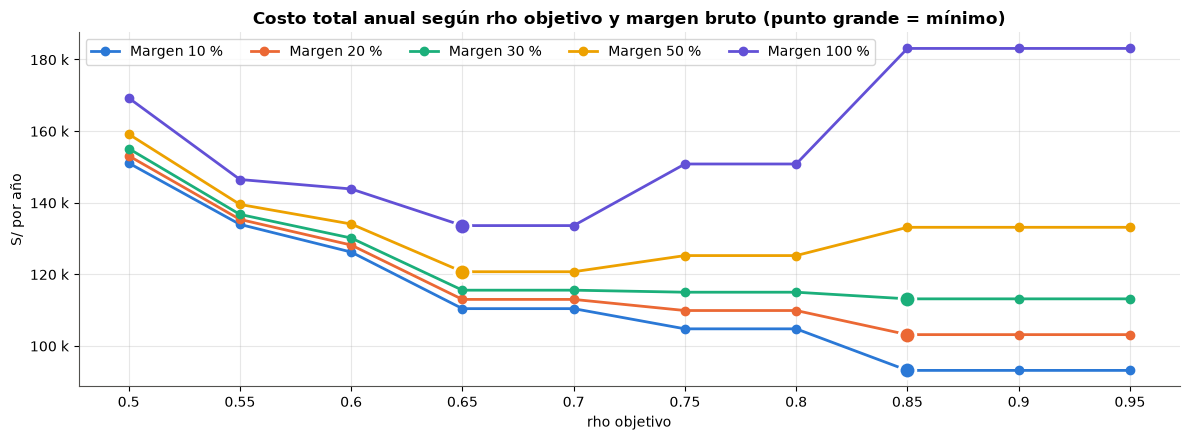

In [11]:
margenes = [0.10, 0.20, 0.30, 0.40, 0.50, 0.75, 1.00]
costo_por_margen = pd.DataFrame({m: sens["Planilla anual (S/)"] + sens["Costo horas extra (S/)"] + m * sens["Venta perdida (S/)"]
                                 for m in margenes})
mejor_rho = costo_por_margen.idxmin()
decision = pd.DataFrame({"Margen bruto": [f"{100 * m:.0f} %" for m in margenes],
                         "rho que minimiza el costo": mejor_rho.values,
                         "Plan": [sens.loc[r, "Plan"] for r in mejor_rho],
                         "Costo total (S/)": costo_por_margen.min().values,
                         "Ahorro vs rho 0.85 (S/)": (costo_por_margen.loc[0.85] - costo_por_margen.min()).values})
display(decision.style.format({"rho que minimiza el costo": "{:.2f}", "Costo total (S/)": "{:,.0f}",
                               "Ahorro vs rho 0.85 (S/)": "{:,.0f}"}).hide(axis="index"))

# Margen a partir del cual conviene el plan de rho 0.65 frente al de rho 0.85
a, b = sens.loc[0.65], sens.loc[0.85]
margen_eq = (costo_personal(a) - costo_personal(b)) / (b["Venta perdida (S/)"] - a["Venta perdida (S/)"])
print(f"El plan de rho 0.65 conviene sobre el de rho 0.85 cuando el margen bruto supera {100 * margen_eq:.0f} %")

fig, ax = plt.subplots()
paleta = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]
for color, m in zip(paleta, [0.10, 0.20, 0.30, 0.50, 1.00]):
    y = costo_por_margen[m]
    ax.plot(x_rho, y, marker="o", lw=2, color=color, label=f"Margen {100 * m:.0f} %")
    ax.plot(str(y.idxmin()), y.min(), marker="o", ms=12, color=color, mec="white", mew=2)
ax.set_title("Costo total anual según rho objetivo y margen bruto (punto grande = mínimo)", fontweight="bold")
ax.set_xlabel("rho objetivo"); ax.set_ylabel("S/ por año"); ax.legend(ncol=5)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f} k")
plt.tight_layout(); plt.show()

## 8. Conclusiones

**Validación.** Con $T = 20$ min y $p = 0.28$ la operación actual simulada reproduce la pérdida de ruta (36.6 % vs 36.4 %) y la cancelación (10.3 % vs 10 %) de 2025. La simulación muestra además que la cola del pico 9–10 h se arrastra hasta las 12–13 h, efecto que el análisis $M/M/c$ hora por hora no captura.

**1. Actual vs. óptimo.** El plan MILP reduce la espera media de 20.3 a 3.1 min y la cancelación de 10.3 % a 1.6 %. La recuperación real de ventas es **84 %, no el 95 %** que supone el ROI original: el beneficio neto baja a ≈ S/ 502 mil/año (ROI ≈ 1 520 % en lugar de 1 687 %), valorando la venta perdida a precio de venta.

**Puntos débiles del plan** (que el MILP no ve porque mira solo $\rho_h$):
* **17:00 h**: un solo despachador (FT-3). Con $c = 1$, cualquier pedido que llega con él ocupado espera en promedio un servicio completo (44.5 min > T), por eso se pierde la ruta en ≈ 38 % de los pedidos de esa hora. $\rho \le 0.85$ **no garantiza** una espera baja cuando hay 1 servidor.
* **12:00 h**: los 3 FT-1 almuerzan a la vez y la capacidad cae de 6 a 3 (≈ 14 % de pérdida). El MILP tiene óptimos alternativos con el mismo costo que escalonan almuerzos (FT-1 / FT-2).

**2. Crecimiento.** El plan aguanta hasta **+20 %** de demanda ($\rho$ pico = 1.0) con 3 % de cancelación; a +50 % llega a 6 %, todavía mejor que la situación actual.

**3. Ausentismo.** Con 10 % de ausentismo diario la cancelación del plan óptimo sube a 3.2 % (el doble), frente a 12.4 % del sistema actual. Conviene tener un reemplazo o polivalencia para las 9–11 h.

**4. Horas extra.** Despachar lo pendiente después de las 18:00 cuesta poco: ≈ 134 h/año en la situación actual y 138 h/año con el plan óptimo (≈ S/ 720/año en ambos casos, menos del 1 % de la planilla). Sube con el ausentismo (271 h/año en la situación actual con 15 %), pero en ningún escenario cambia la decisión.

**5. $\rho$ objetivo y margen bruto.** La decisión depende de cómo se valore un pedido cancelado:
* Si el margen bruto es **30 % o menos**, el plan del MILP con $\rho = 0.85$ (6 despachadores) es el de menor costo total.
* Si el margen supera **≈ 33 %**, conviene $\rho = 0.65$ (8 despachadores: FT-1 ×4, FT-3 ×1, PT-1 ×3): ahorra ≈ S/ 5 mil/año con 40 % de margen y ≈ S/ 49 mil/año a precio de venta.

En una distribuidora mayorista el margen bruto suele ser bajo, así que lo más probable es que $\rho = 0.85$ siga siendo la mejor opción; conviene confirmarlo con el margen real de DENLU.

**Limitaciones:** servicio exponencial y ticket constante (no se usó el CSV), situación actual sin almuerzos, días independientes (lo pendiente no pasa al día siguiente). Solo se pagan como extra las horas después de las 18:00: terminar un pedido después del fin de un turno individual (p. ej. FT-1 a las 17:00) no se cuenta, y se aplica el 25 % de sobretasa a todas las horas extra (desde la tercera hora del día la ley exige 35 %).